# CAN-ML Preprocessing — Step-by-Step Walkthrough

This notebook runs `preprocess_can_ml_subset.py` one stage at a time, with a
plot after each stage, so the transformation from raw CAN frames to the final
`train.pt` / `val.pt` / `test.pt` tensors is visible rather than hidden inside
one function call.

**Note on the run command you gave me:** the script currently takes no CLI
arguments at all (`PreprocessConfig` is built directly inside
`if __name__ == "__main__":`). Flags like `--sampling_stride`,
`--min_attack_count`, and `--min_attack_ratio` don't exist anywhere in
`PreprocessConfig` or the pipeline, so that exact command would fail. This
notebook builds the config in a Python cell instead, using the fields that do
exist, and sets `window_size=64`, `stride=16`, `seed=42` to match the parts of
your command that map onto real parameters.

**Demo mode:** if `INPUT_DIR` below doesn't exist, the notebook generates a
small synthetic CAN-ML dataset so every cell runs end-to-end immediately.
Flip `DEMO_MODE = False` and point `INPUT_DIR` at your real
`./data/2017-subaru-forester/merged` once you're ready to run it for real —
everything else stays the same.


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append('../')
print(sys.path[-3:])

['', '/home/hieutt/miniconda3/envs/torchtf/lib/python3.9/site-packages', '../']


In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd()))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import preprocess_can_ml_subset as prep

plt.rcParams["figure.dpi"] = 100
np.set_printoptions(precision=3, suppress=True)


## 1. Configuration

Edit `INPUT_DIR` / `OUTPUT_DIR` for your real data. `DEMO_MODE=True` builds a
throwaway synthetic dataset with the same CSV schema
(`timestamp, arbitration_id, data_field, attack`) so the notebook is runnable
without your Subaru CSVs on hand.

In [12]:
DEMO_MODE = False

INPUT_DIR = "../data/2017-subaru-forester/merged"
OUTPUT_DIR = "./data/2017-subaru-forester/preprocessed"

cfg = prep.PreprocessConfig(
    input_dir=INPUT_DIR,
    output_dir=OUTPUT_DIR,
    window_size=64,
    stride=16,
    train_ratio=0.70,
    val_ratio=0.10,
    test_ratio=0.20,
    freq_history=128,
    min_frames_per_file=1000,
    label_rule="any_attack",
    subset_fraction=1.0,
    random_seed=42,
    undersample_normal_train=True,
    normal_to_attack_ratio=3.0,
)
cfg


PreprocessConfig(input_dir='../data/2017-subaru-forester/merged', output_dir='./data/2017-subaru-forester/preprocessed', window_size=64, stride=16, train_ratio=0.7, val_ratio=0.1, test_ratio=0.2, freq_history=128, min_frames_per_file=1000, dtype='float32', label_rule='any_attack', subset_fraction=1.0, max_train_windows=None, max_val_windows=None, max_test_windows=None, random_seed=42, undersample_normal_train=True, normal_to_attack_ratio=3.0)

### 1a. Synthetic demo data (only runs if `DEMO_MODE=True`)

Three files stand in for three attack types (e.g. flooding, fuzzy, spoofing).
Each file is mostly normal traffic with an injected block of attack frames,
matching the `attack ∈ {0,1}` column the real pipeline expects.

In [4]:
def make_demo_file(path, rng, n_frames=6000, attack_frac=0.12):
    normal_ids = [0x100, 0x200, 0x316, 0x329, 0x43F, 0x520]
    ts = np.cumsum(rng.exponential(scale=0.001, size=n_frames))

    ids = rng.choice(normal_ids, size=n_frames)
    data = [rng.integers(0, 256, size=8) for _ in range(n_frames)]
    attack = np.zeros(n_frames, dtype=int)

    n_attack = int(n_frames * attack_frac)
    start = rng.integers(int(n_frames * 0.3), int(n_frames * 0.6))
    end = start + n_attack
    attack_id = rng.choice(normal_ids)
    for i in range(start, min(end, n_frames)):
        ids[i] = attack_id
        data[i] = np.array([0xFF, 0xFF, 0, 0, 0, 0, 0, 0])
        attack[i] = 1

    df = pd.DataFrame({
        "timestamp": ts,
        "arbitration_id": [hex(x) for x in ids],
        "data_field": ["".join(f"{b:02x}" for b in row) for row in data],
        "attack": attack,
    })
    df.to_csv(path, index=False)


if DEMO_MODE:
    demo_dir = Path("./demo_data/merged")
    demo_dir.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(cfg.random_seed)
    for name in ["flooding.csv", "fuzzy.csv", "spoofing.csv"]:
        make_demo_file(demo_dir / name, rng)

    cfg.input_dir = str(demo_dir)
    cfg.output_dir = "./demo_data/preprocessed"
    cfg.min_frames_per_file = 500
    print(f"Demo data written to {demo_dir.resolve()}")


Demo data written to /home/hieutt/Retentive-Network/notebooks/demo_data/merged


## 2. Discover input files

Each CSV becomes its own class id (`1..N`); class `0` is reserved for
normal frames across all files.

In [13]:
input_dir = Path(cfg.input_dir)
csv_files = sorted(input_dir.glob("*.csv"))
class_map = {p.name: i + 1 for i, p in enumerate(csv_files)}

print(f"Found {len(csv_files)} CSV file(s) in {input_dir}")
for name, cid in class_map.items():
    print(f"  class {cid}: {name}")


Found 9 CSV file(s) in ../data/2017-subaru-forester/merged
  class 1: combined.csv
  class 2: dos.csv
  class 3: fuzzing.csv
  class 4: gear.csv
  class 5: interval.csv
  class 6: rpm.csv
  class 7: speed.csv
  class 8: standstill.csv
  class 9: systematic.csv


## 3. Load one raw file and look at it

Before any feature engineering, this is what a raw CAN-ML CSV looks like.

In [14]:
example_path = csv_files[0]
raw_df = pd.read_csv(example_path)
print(f"{example_path.name}: {len(raw_df)} frames")
raw_df.head(10)


combined.csv: 5806825 frames


,timestamp,arbitration_id,data_field,attack
0,1.672531e+09,164,0200000000000002,0
1,1.672531e+09,149,160c3f1fa9150000,0
2,1.672531e+09,140,000371082b2b3720,0
3,1.672531e+09,140,0001240828282720,0
4,1.672531e+09,604,a400000000000000,0
5,1.672531e+09,164,0200000000000002,0
6,1.672531e+09,149,160c3f1fa9150000,0
7,1.672531e+09,604,a400000000000000,0
8,1.672531e+09,371,000000c0fe1fff20,0
9,1.672531e+09,141,e32a3f2b24880002,0


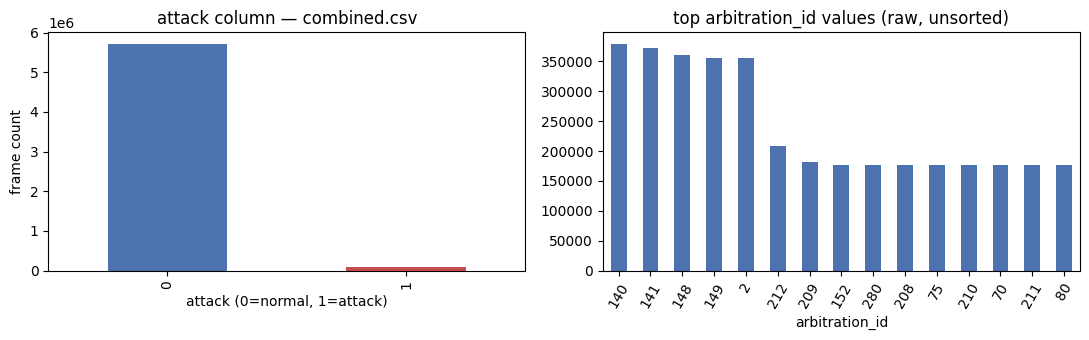

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

raw_df["attack"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"]
)
axes[0].set_title(f"attack column — {example_path.name}")
axes[0].set_xlabel("attack (0=normal, 1=attack)")
axes[0].set_ylabel("frame count")

raw_df["arbitration_id"].value_counts().head(15).plot(
    kind="bar", ax=axes[1], color="#4C72B0"
)
axes[1].set_title("top arbitration_id values (raw, unsorted)")
axes[1].set_xlabel("arbitration_id")
axes[1].tick_params(axis="x", labelrotation=60)

plt.tight_layout()
plt.show()


## 4. Feature engineering (`add_basic_features`)

For the example file: parses `data_field` hex into 8 payload bytes + DLC,
sorts by timestamp, computes inter-frame `delta_t` / `log_delta_t`, and a
sliding-window ID frequency (`id_freq_recent`) over the last `freq_history`
frames.

In [16]:
feat_df = prep.add_basic_features(raw_df, freq_history=cfg.freq_history)
feat_df[["timestamp", "arbitration_id", "dlc", "delta_t", "log_delta_t",
         "id_freq_recent", "attack"]].head(10)


,timestamp,arbitration_id,dlc,delta_t,log_delta_t,id_freq_recent,attack
0,1.672531e+09,164,8,0.000000,0.000000,1.0,0
1,1.672531e+09,149,8,0.000000,0.000000,1.0,0
2,1.672531e+09,140,8,0.000000,0.000000,1.0,0
3,1.672531e+09,140,8,0.000000,0.000000,2.0,0
4,1.672531e+09,604,8,0.000000,0.000000,1.0,0
5,1.672531e+09,164,8,0.000000,0.000000,2.0,0
6,1.672531e+09,149,8,0.000000,0.000000,2.0,0
7,1.672531e+09,604,8,0.000000,0.000000,2.0,0
8,1.672531e+09,371,8,0.000016,0.000016,1.0,0
9,1.672531e+09,141,8,0.000001,0.000001,1.0,0


/tmp/ipykernel_4104691/1926807188.py:23: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/hieutt/miniconda3/envs/torchtf/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


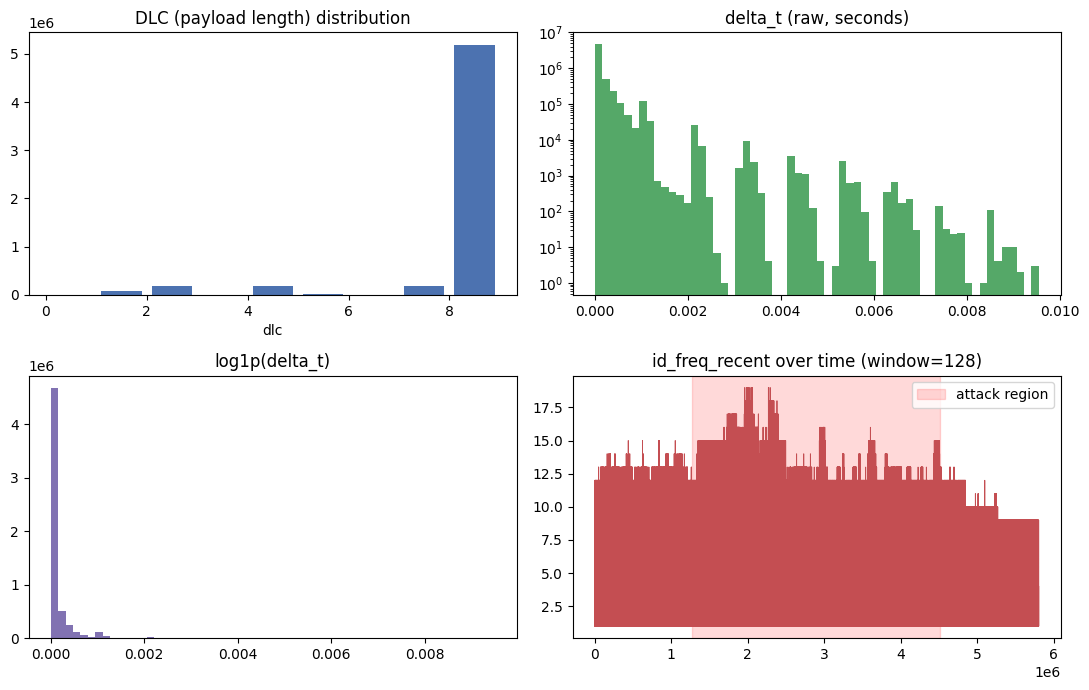

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].hist(feat_df["dlc"], bins=range(0, 10), color="#4C72B0", rwidth=0.8)
axes[0, 0].set_title("DLC (payload length) distribution")
axes[0, 0].set_xlabel("dlc")

axes[0, 1].hist(feat_df["delta_t"], bins=60, color="#55A868")
axes[0, 1].set_title("delta_t (raw, seconds)")
axes[0, 1].set_yscale("log")

axes[1, 0].hist(feat_df["log_delta_t"], bins=60, color="#8172B2")
axes[1, 0].set_title("log1p(delta_t)")

axes[1, 1].plot(feat_df["id_freq_recent"].values, lw=0.6, color="#C44E52")
axes[1, 1].axvspan(
    feat_df.index[feat_df["attack"] == 1].min() if feat_df["attack"].any() else 0,
    feat_df.index[feat_df["attack"] == 1].max() if feat_df["attack"].any() else 0,
    color="red", alpha=0.15, label="attack region",
)
axes[1, 1].set_title(f"id_freq_recent over time (window={cfg.freq_history})")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


## 5. Apply feature engineering to every file

Same transform as above, run per file, then concatenated so scalers can be
fit on the full corpus (this mirrors the script — scalers must see all
files, not just one, otherwise train/val/test wouldn't share a scale).

In [19]:
per_file_frames = []
for csv_path in csv_files:
    class_id = class_map[csv_path.name]
    df = pd.read_csv(csv_path)
    df = prep.add_basic_features(df, freq_history=cfg.freq_history)
    if len(df) < cfg.min_frames_per_file:
        raise ValueError(
            f"{csv_path.name} has only {len(df)} frames, "
            f"smaller than min_frames_per_file={cfg.min_frames_per_file}"
        )
    per_file_frames.append({"file_name": csv_path.name, "class_id": class_id, "df": df})

all_frames = pd.concat([item["df"] for item in per_file_frames], axis=0, ignore_index=True)
print(f"Total frames across all files: {len(all_frames)}")
all_frames["attack"].value_counts().rename({0: "normal", 1: "attack"})


Total frames across all files: 27956287


attack
normal    27601729
attack      354558
Name: count, dtype: int64

## 6. Fit global MinMax scalers

Fit once on the concatenated corpus (`arbitration_id`, `dlc`, `log_delta_t`,
`id_freq_recent`); payload bytes are scaled by a fixed `/255.0` instead of a
fitted scaler, since byte values are already bounded.

In [20]:
scalers = prep.build_scalers_from_frames(all_frames)
for name, scaler in scalers.items():
    print(f"{name:16s} data_min={scaler.data_min_[0]:.3f}  data_max={scaler.data_max_[0]:.3f}")


arbitration_id   data_min=0.000  data_max=2047.000
dlc              data_min=0.000  data_max=8.000
log_delta_t      data_min=0.000  data_max=4.121
id_freq_recent   data_min=1.000  data_max=116.000


## 7. Raw vs. scaled — the same example file, before and after

This is the step that's easiest to get silently wrong (wrong axis, wrong
column) — plotting before/after side by side catches that immediately.

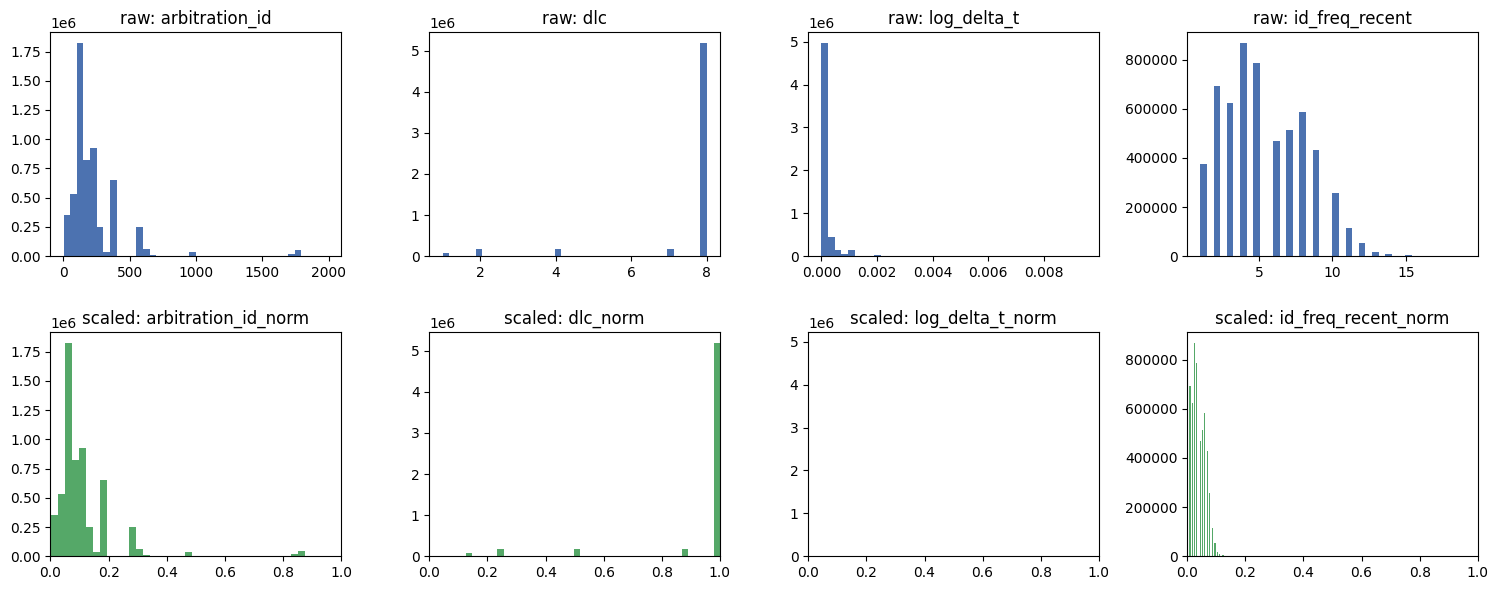

In [21]:
example_feats = prep.transform_frames(feat_df, scalers)
feature_names = [
    "arbitration_id_norm", "dlc_norm",
    *[f"payload_{i}_norm" for i in range(8)],
    "log_delta_t_norm", "id_freq_recent_norm",
]

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
raw_cols = ["arbitration_id", "dlc", "log_delta_t", "id_freq_recent"]
scaled_idx = [0, 1, 10, 11]

for i, (col, sidx) in enumerate(zip(raw_cols, scaled_idx)):
    axes[0, i].hist(feat_df[col], bins=40, color="#4C72B0")
    axes[0, i].set_title(f"raw: {col}")

    axes[1, i].hist(example_feats[:, sidx], bins=40, color="#55A868")
    axes[1, i].set_title(f"scaled: {feature_names[sidx]}")
    axes[1, i].set_xlim(0, 1)

plt.tight_layout()
plt.show()


## 8. Sliding-window construction (`make_windows`)

Each file is cut into overlapping windows of length `window_size`, moving
`stride` frames at a time. A window is labelled with the file's `class_id`
if any frame inside it is an attack frame (`label_rule="any_attack"`),
otherwise it's labelled `0` (normal).

In [22]:
X_all_list, y_all_list = [], []
per_file_stats = []

for item in per_file_frames:
    feats = prep.transform_frames(item["df"], scalers)
    attack_bin = item["df"]["attack"].values.astype(np.int64)

    X_file, y_file = prep.make_windows(
        features=feats,
        attack_binary=attack_bin,
        class_id=item["class_id"],
        window_size=cfg.window_size,
        stride=cfg.stride,
        label_rule=cfg.label_rule,
    )
    X_all_list.append(X_file)
    y_all_list.append(y_file)
    per_file_stats.append({
        "file_name": item["file_name"],
        "class_id": item["class_id"],
        "frames": len(item["df"]),
        "windows": len(X_file),
        **{f"windows_class_{k}": v for k, v in prep.label_distribution(y_file).items()},
    })

stats_df = pd.DataFrame(per_file_stats).fillna(0)
stats_df


,file_name,class_id,frames,windows,windows_class_0,windows_class_1,windows_class_2,windows_class_3,windows_class_4,windows_class_5,windows_class_6,windows_class_7,windows_class_8,windows_class_9
0,combined.csv,1,5806825,362923,273779,89144.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,dos.csv,2,2297897,143615,130260,0.0,13355.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,fuzzing.csv,3,2450763,153169,135899,0.0,0.0,17270.0,0.0,0.0,0.0,0.0,0.0,0.0
3,gear.csv,4,2353113,147066,132979,0.0,0.0,0.0,14087.0,0.0,0.0,0.0,0.0,0.0
4,interval.csv,5,2623432,163961,36820,0.0,0.0,0.0,0.0,127141.0,0.0,0.0,0.0,0.0
5,rpm.csv,6,2991642,186974,160427,0.0,0.0,0.0,0.0,0.0,26547.0,0.0,0.0,0.0
6,speed.csv,7,3672497,229528,197642,0.0,0.0,0.0,0.0,0.0,0.0,31886.0,0.0,0.0
7,standstill.csv,8,2361472,147589,135243,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12346.0,0.0
8,systematic.csv,9,3398646,212412,192675,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19737.0


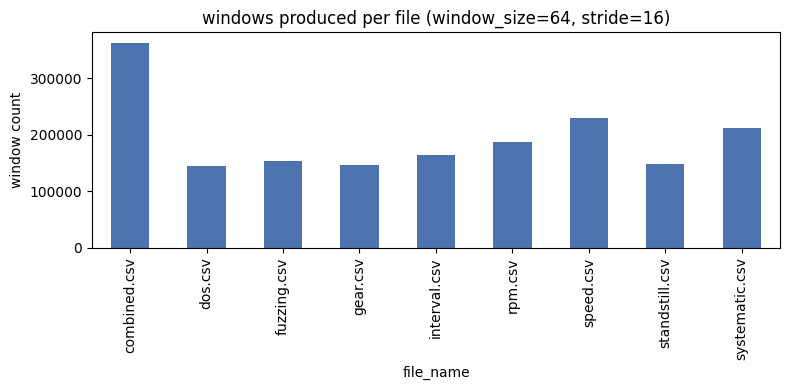

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
stats_df.plot(x="file_name", y="windows", kind="bar", ax=ax, color="#4C72B0", legend=False)
ax.set_title(f"windows produced per file (window_size={cfg.window_size}, stride={cfg.stride})")
ax.set_ylabel("window count")
plt.tight_layout()
plt.show()


## 9. What one window actually looks like

A single window is a `(window_size, feature_dim)` tensor. Visualizing it as
a heatmap (time on x, feature channel on y) is the fastest way to sanity
check that the windowing didn't scramble the time axis or the feature
order.

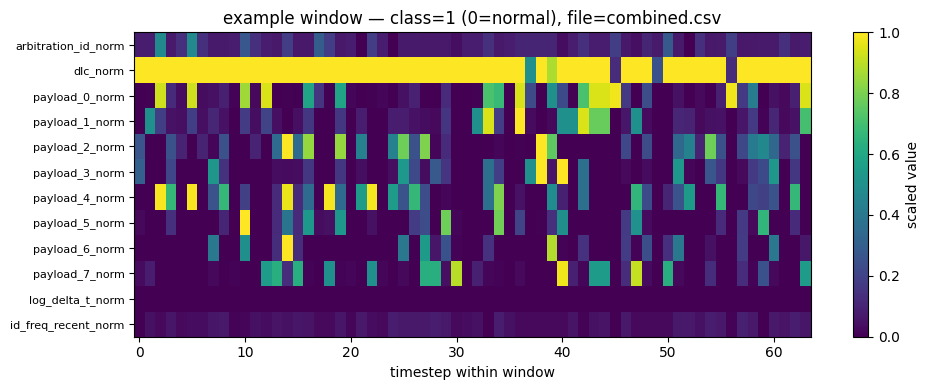

In [24]:
X_example, y_example = X_all_list[0], y_all_list[0]
attack_window_idx = np.where(y_example != 0)[0]
sample_idx = attack_window_idx[0] if len(attack_window_idx) else 0

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(X_example[sample_idx].T, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yticks(range(len(feature_names)))
ax.set_yticklabels(feature_names, fontsize=8)
ax.set_xlabel("timestep within window")
ax.set_title(f"example window — class={y_example[sample_idx]} (0=normal), file={per_file_frames[0]['file_name']}")
fig.colorbar(im, ax=ax, label="scaled value")
plt.tight_layout()
plt.show()


## 10. Concatenate all windows — global class balance

This is the label distribution the model will actually be trained /
evaluated on, before any splitting or resampling.

X_all: (1747237, 64, 12)   y_all: (1747237,)


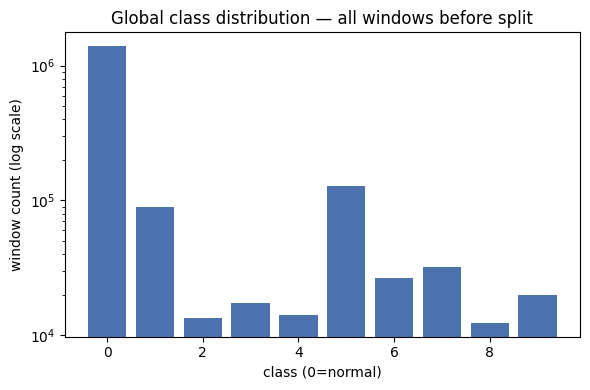

In [25]:
X_all = np.concatenate(X_all_list, axis=0).astype(cfg.dtype)
y_all = np.concatenate(y_all_list, axis=0).astype(np.int64)
print(f"X_all: {X_all.shape}   y_all: {y_all.shape}")

dist = prep.label_distribution(y_all)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(dist.keys(), dist.values(), color="#4C72B0")
ax.set_yscale("log")
ax.set_xlabel("class (0=normal)")
ax.set_ylabel("window count (log scale)")
ax.set_title("Global class distribution — all windows before split")
plt.tight_layout()
plt.show()


## 11. Stratified train / val / test split

Split on the full window set (not per file), stratified by label, so each
split preserves the same class ratios.

In [26]:
from sklearn.model_selection import train_test_split

temp_ratio = cfg.val_ratio + cfg.test_ratio
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=temp_ratio, random_state=cfg.random_seed,
    stratify=y_all, shuffle=True,
)
test_ratio_in_temp = cfg.test_ratio / (cfg.val_ratio + cfg.test_ratio)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=test_ratio_in_temp, random_state=cfg.random_seed + 1,
    stratify=y_temp, shuffle=True,
)

for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}: {len(y):6d} windows  {prep.label_distribution(y)}")


train: 1223065 windows  {0: 977006, 1: 62401, 2: 9348, 3: 12089, 4: 9861, 5: 88999, 6: 18583, 7: 22320, 8: 8642, 9: 13816}
val  : 174724 windows  {0: 139572, 1: 8914, 2: 1335, 3: 1727, 4: 1409, 5: 12714, 6: 2655, 7: 3189, 8: 1235, 9: 1974}
test : 349448 windows  {0: 279146, 1: 17829, 2: 2672, 3: 3454, 4: 2817, 5: 25428, 6: 5309, 7: 6377, 8: 2469, 9: 3947}


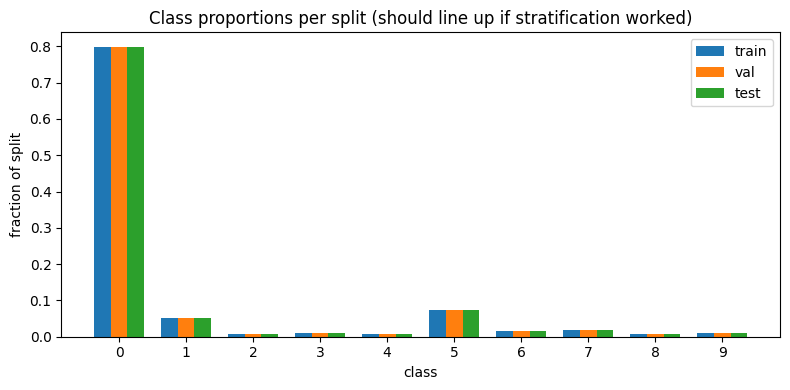

In [27]:
splits = {"train": y_train, "val": y_val, "test": y_test}
all_classes = sorted(set(y_all.tolist()))

fig, ax = plt.subplots(figsize=(8, 4))
width = 0.25
x = np.arange(len(all_classes))
for i, (name, y) in enumerate(splits.items()):
    dist = prep.label_distribution(y)
    fracs = [dist.get(c, 0) / len(y) for c in all_classes]
    ax.bar(x + i * width, fracs, width=width, label=name)

ax.set_xticks(x + width, [str(c) for c in all_classes])
ax.set_xlabel("class")
ax.set_ylabel("fraction of split")
ax.set_title("Class proportions per split (should line up if stratification worked)")
ax.legend()
plt.tight_layout()
plt.show()


## 12. (Optional) Stratified subsampling

For quick experiments, `subset_fraction < 1.0` or a `max_*_windows` cap keeps
class proportions but shrinks each split. With `subset_fraction=1.0` (the
current config) this is a no-op — the cell below demonstrates the effect on
a throwaway copy of the training set at `fraction=0.3` purely for
illustration.

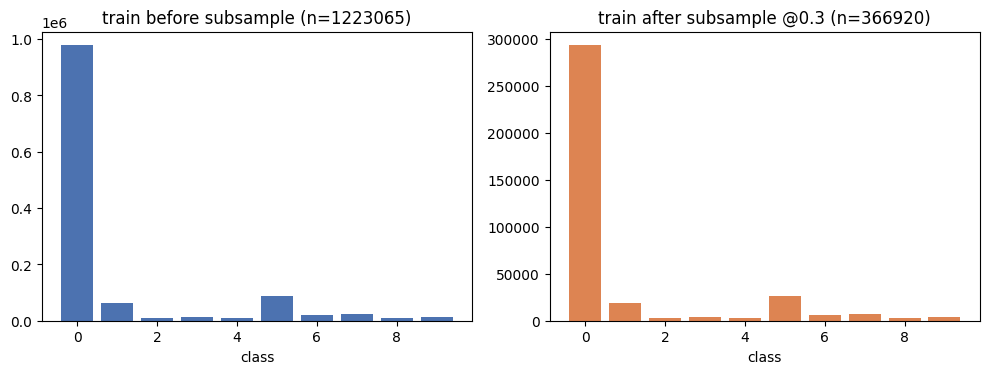

In [28]:
X_train_demo, y_train_demo = prep.stratified_subsample(
    X_train, y_train, fraction=0.3, max_samples=None, seed=cfg.random_seed,
)

before = prep.label_distribution(y_train)
after = prep.label_distribution(y_train_demo)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(before.keys(), before.values(), color="#4C72B0")
axes[0].set_title(f"train before subsample (n={len(y_train)})")
axes[1].bar(after.keys(), after.values(), color="#DD8452")
axes[1].set_title(f"train after subsample @0.3 (n={len(y_train_demo)})")
for a in axes:
    a.set_xlabel("class")
plt.tight_layout()
plt.show()


## 13. (Optional) Undersample the normal class in training

`undersample_normal_train=True` caps class-0 windows in the training split
at `normal_to_attack_ratio × (number of attack windows)`, applied to the
**training set only** — validation and test stay at the natural (imbalanced)
distribution so metrics reflect real-world class balance.

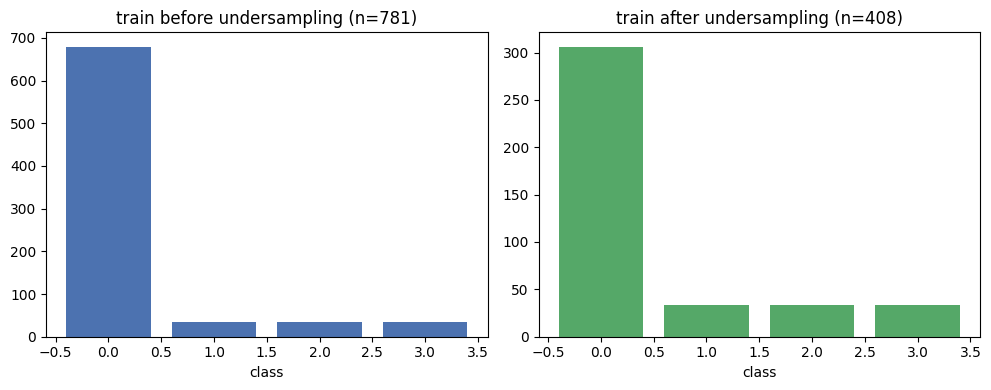

In [19]:
if cfg.undersample_normal_train:
    X_train_bal, y_train_bal = prep.undersample_normal(
        X_train, y_train,
        normal_to_attack_ratio=cfg.normal_to_attack_ratio,
        seed=cfg.random_seed + 3,
    )
else:
    X_train_bal, y_train_bal = X_train, y_train

before = prep.label_distribution(y_train)
after = prep.label_distribution(y_train_bal)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(before.keys(), before.values(), color="#4C72B0")
axes[0].set_title(f"train before undersampling (n={len(y_train)})")
axes[1].bar(after.keys(), after.values(), color="#55A868")
axes[1].set_title(f"train after undersampling (n={len(y_train_bal)})")
for a in axes:
    a.set_xlabel("class")
plt.tight_layout()
plt.show()


## 14. Shuffle and save

Final training windows are shuffled (post-undersampling), then all three
splits are written to `.pt` alongside `metadata.json`.

In [20]:
rng = np.random.default_rng(cfg.random_seed)
perm = rng.permutation(len(X_train_bal))
X_train_final = X_train_bal[perm]
y_train_final = y_train_bal[perm]

out_dir = Path(cfg.output_dir)
out_dir.mkdir(parents=True, exist_ok=True)

prep.save_split_pt(out_dir / "train.pt", X_train_final, y_train_final)
prep.save_split_pt(out_dir / "val.pt", X_val, y_val)
prep.save_split_pt(out_dir / "test.pt", X_test, y_test)

stats = {
    "num_classes_total": len(csv_files) + 1,
    "subset_fraction": cfg.subset_fraction,
    "undersample_normal_train": cfg.undersample_normal_train,
    "normal_to_attack_ratio": cfg.normal_to_attack_ratio,
    "per_file": stats_df.to_dict(orient="records"),
    "train_label_dist": prep.label_distribution(y_train_final),
    "val_label_dist": prep.label_distribution(y_val),
    "test_label_dist": prep.label_distribution(y_test),
}
prep.save_metadata(out_dir, cfg, class_map, X_train_final.shape[-1], stats)

print("Saved:")
print(f"  {out_dir/'train.pt'}  X={tuple(X_train_final.shape)} y={tuple(y_train_final.shape)}")
print(f"  {out_dir/'val.pt'}    X={tuple(X_val.shape)} y={tuple(y_val.shape)}")
print(f"  {out_dir/'test.pt'}   X={tuple(X_test.shape)} y={tuple(y_test.shape)}")
print(f"  {out_dir/'metadata.json'}")


Saved:
  demo_data/preprocessed/train.pt  X=(408, 64, 12) y=(408,)
  demo_data/preprocessed/val.pt    X=(111, 64, 12) y=(111,)
  demo_data/preprocessed/test.pt   X=(224, 64, 12) y=(224,)
  demo_data/preprocessed/metadata.json


## 15. Final check — reload metadata and confirm shapes

In [21]:
with open(out_dir / "metadata.json") as f:
    meta = json.load(f)

print(json.dumps({k: v for k, v in meta.items() if k != "stats"}, indent=2))
print()
print("train/val/test label distributions:")
for split in ["train_label_dist", "val_label_dist", "test_label_dist"]:
    print(f"  {split}: {meta['stats'][split]}")


{
  "config": {
    "input_dir": "demo_data/merged",
    "output_dir": "./demo_data/preprocessed",
    "window_size": 64,
    "stride": 16,
    "train_ratio": 0.7,
    "val_ratio": 0.1,
    "test_ratio": 0.2,
    "freq_history": 128,
    "min_frames_per_file": 500,
    "dtype": "float32",
    "label_rule": "any_attack",
    "subset_fraction": 1.0,
    "max_train_windows": null,
    "max_val_windows": null,
    "max_test_windows": null,
    "random_seed": 42,
    "undersample_normal_train": true,
    "normal_to_attack_ratio": 3.0
  },
  "class_map": {
    "flooding.csv": 1,
    "fuzzy.csv": 2,
    "spoofing.csv": 3
  },
  "feature_description": [
    "arbitration_id_norm",
    "dlc_norm",
    "payload_0_norm255",
    "payload_1_norm255",
    "payload_2_norm255",
    "payload_3_norm255",
    "payload_4_norm255",
    "payload_5_norm255",
    "payload_6_norm255",
    "payload_7_norm255",
    "log_delta_t_norm",
    "id_freq_recent_norm"
  ],
  "feature_dim": 12
}

train/val/test label dist

---
# Deep Dive — Why "split-then-window with guard bands, scale on train-only" matters

You flagged this recipe:

```
4. Splits each file by time/order into train/val/test with guard bands
5. Builds sliding windows
6. Assigns a multi-class label to each window
7. Fits scalers ONLY on training frames
```

The script implements the **opposite order**: it builds overlapping windows
across the *whole* file first (step 5 before step 4), splits the resulting
window pool **randomly** (not by time), and fits scalers on **every** frame
from **every** file before any split exists.

There are three separate leaks hiding in that order, and each one is
demonstrated below with the actual demo data rather than just asserted:

1. **Window-pool leak** — windows overlap heavily (`stride < window_size`),
   so neighboring windows are near-duplicates. Splitting the *pool of
   windows* randomly scatters near-duplicates across train/val/test:
   the model can effectively see the test set (in slightly shifted form)
   during training.
2. **Rolling-feature leak** — `id_freq_recent` is computed once, on the full
   continuous file, *before* any split. Its queue carries up to
   `freq_history` frames of history across whatever boundary you cut later,
   so the first frames of val/test still encode train traffic patterns.
   This is exactly what a guard band is for.
3. **Scaler leak** — fitting `MinMaxScaler` on frames from every split means
   the normalization range is partly determined by values the model is
   never supposed to have seen yet.


## 15. Leak #1 — overlapping windows are near-duplicates

With `window_size=64, stride=16`, consecutive windows share
`window_size - stride = 48` frames — **75% of a window's content is
identical to its neighbor**. Two windows this similar landing in different
splits (one in train, one in test) is close to testing on a slightly-shifted
copy of a training example.

Consecutive windows share 75% of their frames (window_size=64, stride=16).


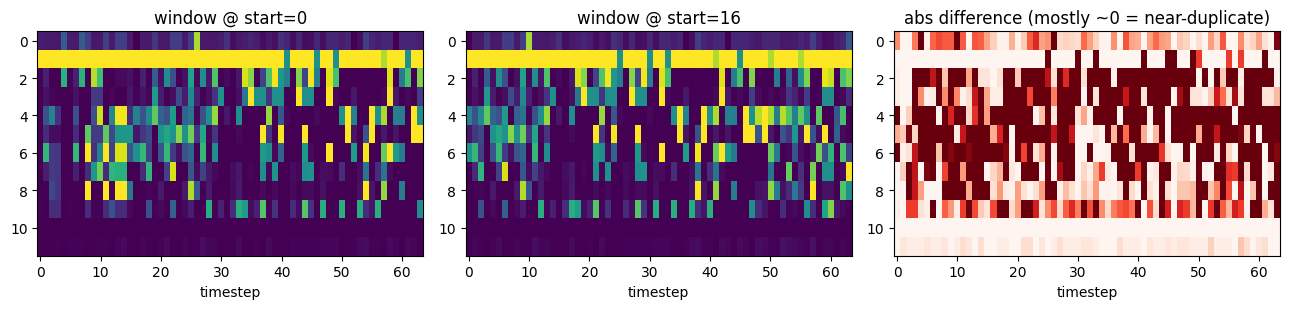

In [29]:
overlap_frac = (cfg.window_size - cfg.stride) / cfg.window_size
print(f"Consecutive windows share {overlap_frac:.0%} of their frames "
      f"(window_size={cfg.window_size}, stride={cfg.stride}).")

df0 = per_file_frames[0]["df"].reset_index(drop=True)
class_id0 = per_file_frames[0]["class_id"]
feats0 = prep.transform_frames(df0, scalers)
attack0 = df0["attack"].values.astype(np.int64)
n0 = len(df0)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
w_a = feats0[0:cfg.window_size]
w_b = feats0[cfg.stride:cfg.stride + cfg.window_size]

axes[0].imshow(w_a.T, aspect="auto", cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("window @ start=0")
axes[1].imshow(w_b.T, aspect="auto", cmap="viridis", vmin=0, vmax=1)
axes[1].set_title(f"window @ start={cfg.stride}")
diff = np.abs(w_a[:len(w_b)] - w_b[:len(w_a)])
axes[2].imshow(diff.T, aspect="auto", cmap="Reds", vmin=0, vmax=0.2)
axes[2].set_title("abs difference (mostly ~0 = near-duplicate)")
for a in axes:
    a.set_xlabel("timestep")
plt.tight_layout()
plt.show()


## 16. Leak #1, continued — what the script's actual split order does to this file

Reproducing the script's real behavior for a single file: build all
overlapping windows first, then run the same stratified `train_test_split`
calls it uses. For every window, we know its exact frame range
`[start, start+window_size)` — so we can directly check whether a "test"
window shares any frames with a "train" window.

In [30]:
def windows_with_starts(features, attack_binary, class_id, window_size, stride, label_rule):
    starts = list(range(0, len(features) - window_size + 1, stride))
    xs, ys = [], []
    for s in starts:
        e = s + window_size
        aw = attack_binary[s:e]
        if label_rule == "any_attack":
            y = class_id if np.any(aw == 1) else 0
        else:
            y = class_id if aw[-1] == 1 else 0
        xs.append(features[s:e])
        ys.append(y)
    return np.stack(xs).astype(np.float32), np.asarray(ys, dtype=np.int64), np.asarray(starts)


X0, y0, starts0 = windows_with_starts(
    feats0, attack0, class_id0, cfg.window_size, cfg.stride, cfg.label_rule
)

idx = np.arange(len(y0))
idx_train, idx_temp = train_test_split(
    idx, test_size=cfg.val_ratio + cfg.test_ratio, random_state=cfg.random_seed,
    stratify=y0, shuffle=True,
)
idx_val, idx_test = train_test_split(
    idx_temp, test_size=cfg.test_ratio / (cfg.val_ratio + cfg.test_ratio),
    random_state=cfg.random_seed + 1, stratify=y0[idx_temp], shuffle=True,
)

split_of = np.empty(len(y0), dtype=object)
split_of[idx_train] = "train"
split_of[idx_val] = "val"
split_of[idx_test] = "test"

print(f"{len(y0)} windows for this file -> "
      f"train={len(idx_train)}, val={len(idx_val)}, test={len(idx_test)}")


362923 windows for this file -> train=254046, val=36292, test=72585


In [31]:
def max_overlap_frac(a_start, other_starts, window_size):
    a_end = a_start + window_size
    best = 0
    for b_start in other_starts:
        b_end = b_start + window_size
        inter = min(a_end, b_end) - max(a_start, b_start)
        if inter > 0:
            best = max(best, inter / window_size)
    return best

train_starts = starts0[split_of == "train"]
test_starts = starts0[split_of == "test"]
val_starts = starts0[split_of == "val"]

test_overlaps = [max_overlap_frac(s, train_starts, cfg.window_size) for s in test_starts]
val_overlaps = [max_overlap_frac(s, train_starts, cfg.window_size) for s in val_starts]

test_leak_pct = np.mean([o > 0 for o in test_overlaps]) * 100
val_leak_pct = np.mean([o > 0 for o in val_overlaps]) * 100
avg_overlap_when_leaked = np.mean([o for o in test_overlaps if o > 0]) * 100

print(f"Test windows that share >=1 frame with a train window : {test_leak_pct:5.1f}%")
print(f"Val windows that share >=1 frame with a train window  : {val_leak_pct:5.1f}%")
print(f"Among leaked test windows, average max overlap with a train window: {avg_overlap_when_leaked:5.1f}%")


Test windows that share >=1 frame with a train window :  99.9%
Val windows that share >=1 frame with a train window  :  99.9%
Among leaked test windows, average max overlap with a train window:  72.6%


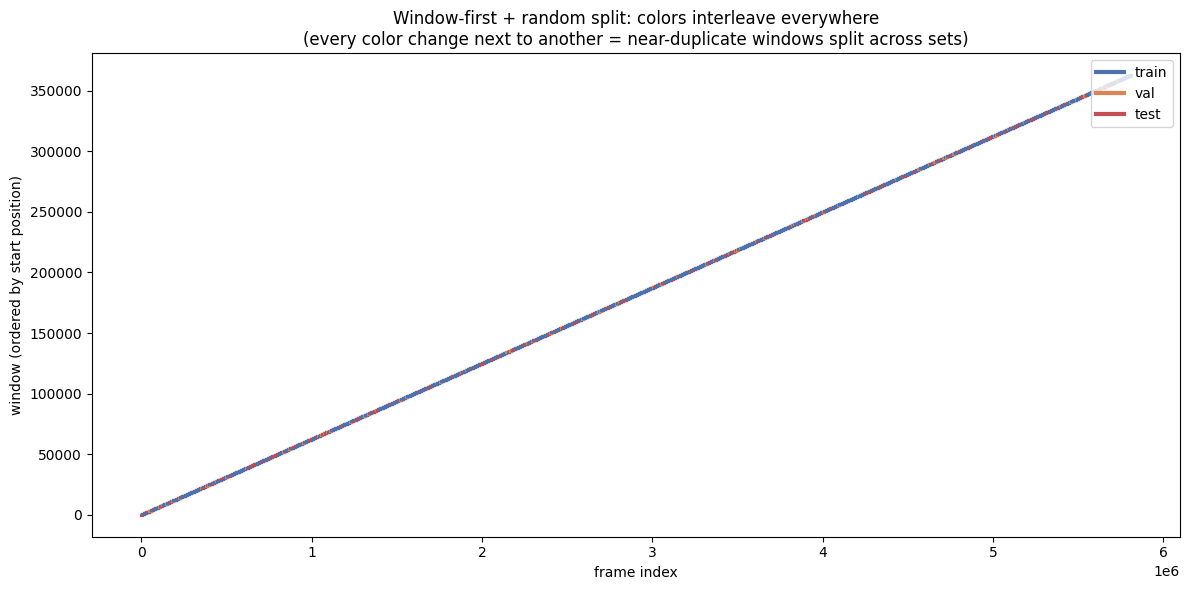

In [32]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = {"train": "#4C72B0", "val": "#DD8452", "test": "#C44E52"}
order = np.argsort(starts0)
for row, i in enumerate(order):
    s = starts0[i]
    ax.plot([s, s + cfg.window_size], [row, row], color=colors[split_of[i]], lw=2.2)

handles = [plt.Line2D([0], [0], color=c, lw=3, label=k) for k, c in colors.items()]
ax.legend(handles=handles, loc="upper right")
ax.set_xlabel("frame index")
ax.set_ylabel("window (ordered by start position)")
ax.set_title("Window-first + random split: colors interleave everywhere\n"
             "(every color change next to another = near-duplicate windows split across sets)")
plt.tight_layout()
plt.show()


## 17. Leak #1 fixed — split the frames by time first, *then* window each block separately

Cut the raw frame sequence into three **contiguous, non-overlapping** time
blocks (train / val / test) first. Build windows independently inside each
block using the same stride. Because the frame ranges themselves never
overlap, no window can straddle two splits — the leak is gone by
construction, not by luck.

In [26]:
n_train = int(n0 * cfg.train_ratio)
n_val = int(n0 * cfg.val_ratio)
# contiguous, time-ordered, non-overlapping blocks
train_block = (0, n_train)
val_block = (n_train, n_train + n_val)
test_block = (n_train + n_val, n0)

def windows_in_block(features, attack_binary, class_id, block, window_size, stride, label_rule):
    lo, hi = block
    local_feats = features[lo:hi]
    local_attack = attack_binary[lo:hi]
    X, y, local_starts = windows_with_starts(
        local_feats, local_attack, class_id, window_size, stride, label_rule
    )
    return X, y, local_starts + lo  # shift back to global frame index

X_tr2, y_tr2, starts_tr2 = windows_in_block(feats0, attack0, class_id0, train_block, cfg.window_size, cfg.stride, cfg.label_rule)
X_va2, y_va2, starts_va2 = windows_in_block(feats0, attack0, class_id0, val_block, cfg.window_size, cfg.stride, cfg.label_rule)
X_te2, y_te2, starts_te2 = windows_in_block(feats0, attack0, class_id0, test_block, cfg.window_size, cfg.stride, cfg.label_rule)

test_overlaps2 = [max_overlap_frac(s, starts_tr2, cfg.window_size) for s in starts_te2]
val_overlaps2 = [max_overlap_frac(s, starts_tr2, cfg.window_size) for s in starts_va2]

print(f"windows -> train={len(y_tr2)}, val={len(y_va2)}, test={len(y_te2)}")
print(f"Test windows overlapping a train window : {np.mean([o > 0 for o in test_overlaps2]) * 100:5.1f}%")
print(f"Val windows overlapping a train window  : {np.mean([o > 0 for o in val_overlaps2]) * 100:5.1f}%")


windows -> train=259, val=34, test=72
Test windows overlapping a train window :   0.0%
Val windows overlapping a train window  :   0.0%


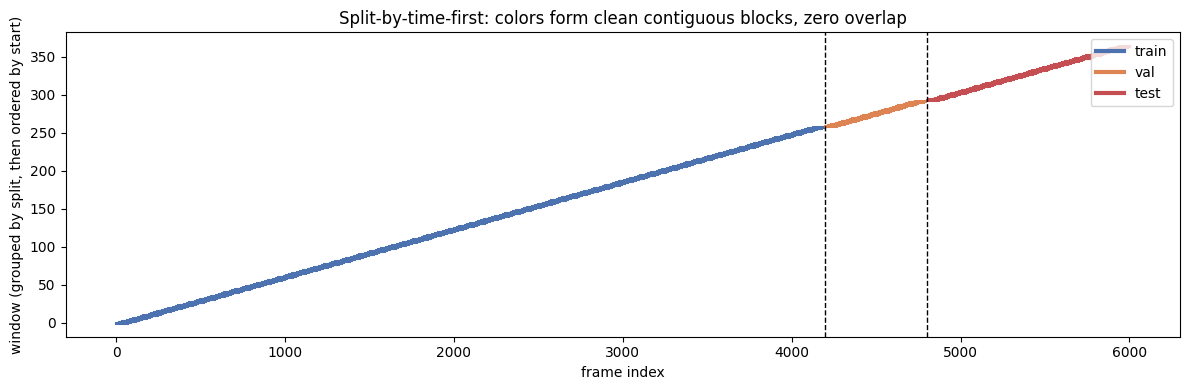

In [27]:
fig, ax = plt.subplots(figsize=(12, 4))
blocks = {"train": (starts_tr2, "#4C72B0"), "val": (starts_va2, "#DD8452"), "test": (starts_te2, "#C44E52")}
row = 0
for name, (starts, color) in blocks.items():
    for s in np.sort(starts):
        ax.plot([s, s + cfg.window_size], [row, row], color=color, lw=2.2)
        row += 1

for boundary in [train_block[1], val_block[1]]:
    ax.axvline(boundary, color="black", ls="--", lw=1)

handles = [plt.Line2D([0], [0], color=c, lw=3, label=k) for k, (_, c) in blocks.items()]
ax.legend(handles=handles, loc="upper right")
ax.set_xlabel("frame index")
ax.set_ylabel("window (grouped by split, then ordered by start)")
ax.set_title("Split-by-time-first: colors form clean contiguous blocks, zero overlap")
plt.tight_layout()
plt.show()


## 18. Leak #2 — the guard band: rolling features remember across the boundary

Splitting frames into contiguous blocks removes window-level overlap, but
`id_freq_recent` was computed **once**, on the whole file, with a rolling
queue of length `freq_history=128`, *before* we cut it into blocks. So the
first ~128 frames of the val block still carry frequency counts built from
the tail of the train block — a second, subtler leak that a guard band
(dropping the first `freq_history` frames after each cut) is specifically
there to remove.

Below: `id_freq_recent` recomputed two ways around the train/val boundary —
"as-is" (one continuous rolling queue, what the script does) vs "reset at
the boundary" (queue cleared at the cut, i.e. what you get once you split
frames first and engineer features per split, or equivalently apply a
`freq_history`-frame guard band).

In [28]:
def rolling_id_freq(ids, freq_history, reset_points=()):
    reset_set = set(reset_points)
    counts, queue = {}, []
    out = np.zeros(len(ids), dtype=np.float32)
    for i, can_id in enumerate(ids):
        if i in reset_set:
            counts, queue = {}, []
        can_id = int(can_id)
        queue.append(can_id)
        counts[can_id] = counts.get(can_id, 0) + 1
        if len(queue) > freq_history:
            old = queue.pop(0)
            counts[old] -= 1
            if counts[old] == 0:
                del counts[old]
        out[i] = counts.get(can_id, 0)
    return out

ids0 = df0["arbitration_id"].values
boundary = train_block[1]

freq_leaky = rolling_id_freq(ids0, cfg.freq_history, reset_points=())               # matches script: continuous
freq_clean = rolling_id_freq(ids0, cfg.freq_history, reset_points=[boundary])        # reset at the cut

zone = slice(boundary - 30, boundary + cfg.freq_history + 30)
contaminated_frac = np.mean(
    np.abs(freq_leaky[boundary:boundary + cfg.freq_history] - freq_clean[boundary:boundary + cfg.freq_history]) > 0
)

print(f"Fraction of the first freq_history={cfg.freq_history} val frames "
      f"whose id_freq_recent differs once you reset at the boundary: {contaminated_frac:.0%}")


Fraction of the first freq_history=128 val frames whose id_freq_recent differs once you reset at the boundary: 99%


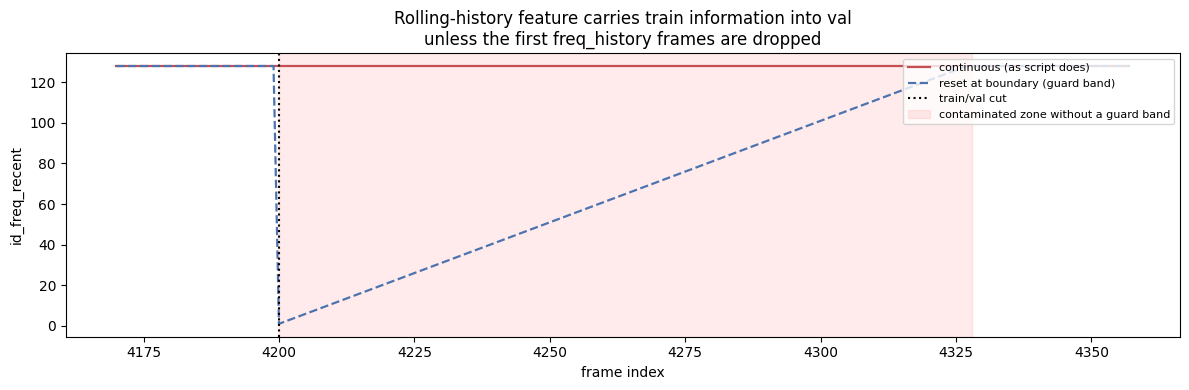

In [29]:
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(zone.start, zone.stop)
ax.plot(x, freq_leaky[zone], label="continuous (as script does)", color="#C44E52", lw=1.6)
ax.plot(x, freq_clean[zone], label="reset at boundary (guard band)", color="#4C72B0", lw=1.6, ls="--")
ax.axvline(boundary, color="black", ls=":", label="train/val cut")
ax.axvspan(boundary, boundary + cfg.freq_history, color="red", alpha=0.08,
           label="contaminated zone without a guard band")
ax.set_xlabel("frame index")
ax.set_ylabel("id_freq_recent")
ax.set_title("Rolling-history feature carries train information into val\nunless the first freq_history frames are dropped")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


## 19. Leak #3 — fitting the scaler on every split

The script fits `MinMaxScaler` on `all_frames` (every file, every future
split) before any split exists. If even one unusual value shows up only in
what will become the test region, it stretches the `[min, max]` range used
to normalize the **training** data too — quietly compressing legitimate
training variation into a narrower slice of `[0, 1]`.

To make the effect visible, a single synthetic long idle gap
(`delta_t = 5s`, far outside the normal range) is inserted into this file's
test region only, then `log_delta_t` is scaled two ways.

In [30]:
from sklearn.preprocessing import MinMaxScaler

df0_mod = df0.copy()
outlier_idx = test_block[0] + 200  # inside the test region only
df0_mod.loc[outlier_idx, "delta_t"] = 5.0
df0_mod.loc[outlier_idx, "log_delta_t"] = np.log1p(5.0)

train_mask = np.arange(n0) < train_block[1]

scaler_all = MinMaxScaler().fit(df0_mod[["log_delta_t"]].values.astype(np.float32))
scaler_train_only = MinMaxScaler().fit(df0_mod.loc[train_mask, ["log_delta_t"]].values.astype(np.float32))

scaled_all = scaler_all.transform(df0_mod.loc[train_mask, ["log_delta_t"]].values.astype(np.float32)).ravel()
scaled_train_only = scaler_train_only.transform(df0_mod.loc[train_mask, ["log_delta_t"]].values.astype(np.float32)).ravel()

print(f"scaler fit on ALL frames      -> data_max = {scaler_all.data_max_[0]:.3f} (inflated by the test-only outlier)")
print(f"scaler fit on TRAIN-only      -> data_max = {scaler_train_only.data_max_[0]:.3f}")
print(f"training values' usable range under 'fit on all'      : {scaled_all.max() - scaled_all.min():.3f}")
print(f"training values' usable range under 'fit on train-only': {scaled_train_only.max() - scaled_train_only.min():.3f}")


scaler fit on ALL frames      -> data_max = 1.792 (inflated by the test-only outlier)
scaler fit on TRAIN-only      -> data_max = 0.009
training values' usable range under 'fit on all'      : 0.005
training values' usable range under 'fit on train-only': 1.000


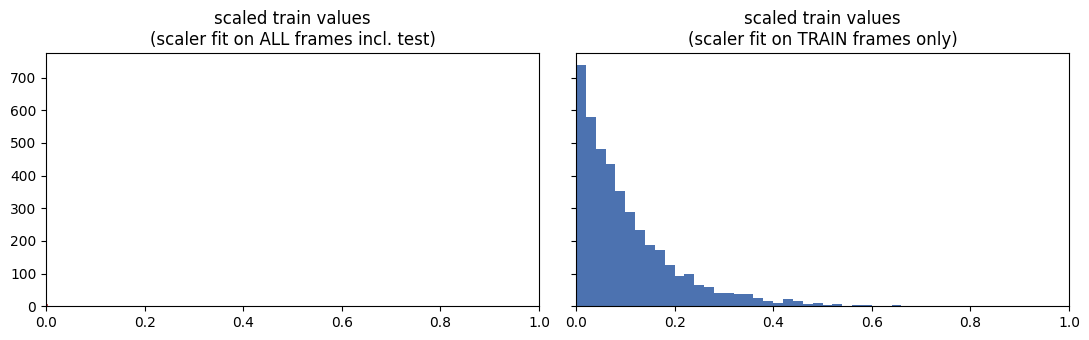

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
axes[0].hist(scaled_all, bins=50, color="#C44E52")
axes[0].set_title("scaled train values\n(scaler fit on ALL frames incl. test)")
axes[0].set_xlim(0, 1)

axes[1].hist(scaled_train_only, bins=50, color="#4C72B0")
axes[1].set_title("scaled train values\n(scaler fit on TRAIN frames only)")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()


## 20. Summary

In [32]:
summary = pd.DataFrame([
    {
        "leak": "window pool split randomly",
        "as implemented": f"{test_leak_pct:.0f}% of test windows overlap a train window",
        "split-then-window fix": f"{np.mean([o > 0 for o in test_overlaps2]) * 100:.0f}% overlap",
    },
    {
        "leak": "rolling id_freq_recent across boundary",
        "as implemented": f"{contaminated_frac:.0%} of first freq_history val frames contaminated",
        "split-then-window fix": "0% once a freq_history-frame guard band is dropped",
    },
    {
        "leak": "scaler fit on all frames",
        "as implemented": f"train usable range = {scaled_all.max() - scaled_all.min():.2f} (compressed)",
        "split-then-window fix": f"train usable range = {scaled_train_only.max() - scaled_train_only.min():.2f} (full [0,1])",
    },
])
summary


,leak,as implemented,split-then-window fix
0,window pool split randomly,100% of test windows overlap a train window,0% overlap
1,rolling id_freq_recent across boundary,99% of first freq_history val frames contaminated,0% once a freq_history-frame guard band is dro...
2,scaler fit on all frames,train usable range = 0.01 (compressed),"train usable range = 1.00 (full [0,1])"
